# 08. Sazonalidade mensal (P2)

**Pergunta 2:** existe sazonalidade mensal consistente, e ela difere entre estados (litoral × semiárido)?

| Entrada | Saída |
|---|---|
| `notificacao_dengue_ne`, `municipio` (tratadas) | perfil mensal por estado, mês de pico e concentração; comparação capital × interior; achados no fim |

**Método.** Mês dos primeiros sintomas (`mes_sintomas`, decisão 9), casos prováveis, 2000 a 2025. Para que os anos
epidêmicos não dominem o perfil, os casos de cada estado-ano viram **proporção mensal** (soma = 100%); só entram
estado-anos com pelo menos 100 casos. A sazonalidade é resumida com estatística circular, em que dezembro e janeiro são
vizinhos:
- **mês de pico**: média circular dos meses, pesada pelos casos;
- **concentração R**: 0 = casos espalhados igualmente no ano, 1 = todos no mesmo mês.

**Litoral × semiárido.** O banco ainda não tem a lista oficial de municípios do semiárido (SUDENE/IBGE). Até ela entrar
como fonte, a seção 5 compara **capital × interior** (todas as capitais do Nordeste são litorâneas, exceto Teresina).
É uma aproximação e está registrada como pendência em `03_decisoes.md`.

**Neste notebook**
1. Dados
2. Nordeste: o padrão se repete todo ano?
3. Perfil médio por estado
4. Mês de pico e consistência por estado
5. Capital × interior
6. Achados

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.append(str(RAIZ / "src"))

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import eda

eda.estilo()

## 1. Dados

In [2]:
MIN_CASOS = 100
mes = eda.casos_mes()
total = eda.consulta("""SELECT count(*) AS n FROM notificacao_dengue_ne
                        WHERE caso_provavel AND ano BETWEEN 2000 AND 2025""").n[0]
print(f"Casos prováveis com mês de sintomas: {mes.casos.sum():,} de {total:,} "
      f"({(total - mes.casos.sum()):,} sem data de sintomas ficam de fora)")


def proporcao_mensal(df, chaves):
    """Proporção (%) dos casos de cada grupo-ano em cada mês; descarta grupo-anos com menos de MIN_CASOS."""
    t = (df.groupby(chaves + ["ano", "mes"], observed=True).casos.sum()
           .unstack("mes", fill_value=0).reindex(columns=range(1, 13), fill_value=0))
    t = t[t.sum(axis=1) >= MIN_CASOS]
    return t.div(t.sum(axis=1), axis=0) * 100


def circulares(prop):
    """Mês de pico e concentração R de cada linha de uma tabela de proporções mensais."""
    return prop.apply(lambda r: pd.Series(eda.estatisticas_circulares(r.to_numpy()), index=["pico", "R"]), axis=1)


prop_ne = proporcao_mensal(mes.assign(regiao="NE"), ["regiao"]).droplevel("regiao")
prop_uf = proporcao_mensal(mes, ["uf"])
circ_ne, circ_uf = circulares(prop_ne), circulares(prop_uf)
print(f"Estado-anos analisados: {len(prop_uf)} de {9 * 26} (os demais têm menos de {MIN_CASOS} casos)")

Casos prováveis com mês de sintomas: 4,169,498 de 4,178,450 (8,952 sem data de sintomas ficam de fora)
Estado-anos analisados: 233 de 234 (os demais têm menos de 100 casos)


## 2. Nordeste: o padrão se repete todo ano?
Cada linha cinza é um ano; a linha azul é a média dos anos.

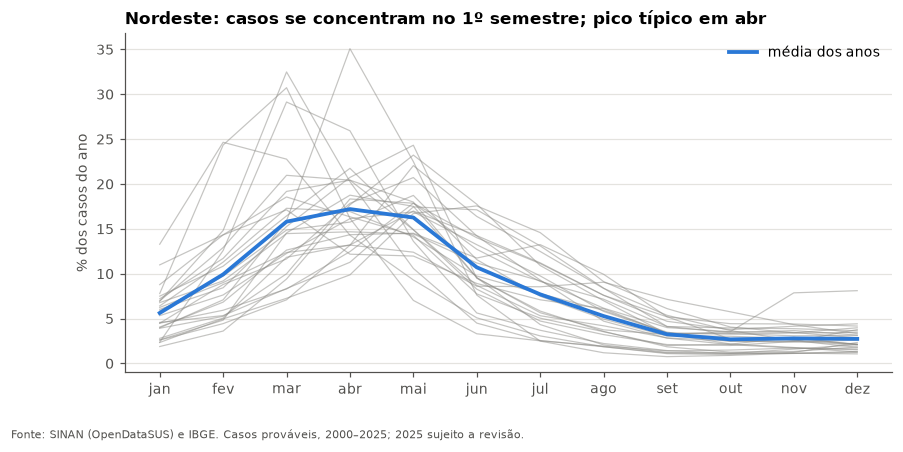

Pico típico: abr (4.4); 77% dos anos com pico a até 1 mês dele
Concentração R: mediana 0.46 (de 0.23 a 0.72)
Casos de janeiro a junho: mediana 75% do ano (de 59% a 92%)


In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for _, linha in prop_ne.iterrows():
    ax.plot(range(1, 13), linha, color=eda.COR["referencia"], lw=0.8, alpha=0.5)
media_ne = prop_ne.mean()
ax.plot(range(1, 13), media_ne, color=eda.COR["principal"], lw=2.5, label="média dos anos")
ax.set_xticks(range(1, 13), eda.MESES)
ax.set_ylabel("% dos casos do ano")
pico_ne = eda.media_circular(circ_ne.pico)
ax.set_title(f"Nordeste: casos se concentram no 1º semestre; pico típico em {eda.nome_mes(pico_ne)}")
ax.legend(loc="upper right")
eda.nota(fig)
plt.show()

perto = (eda.distancia_meses(circ_ne.pico, pico_ne) <= 1).mean() * 100
semestre = prop_ne[range(1, 7)].sum(axis=1)
print(f"Pico típico: {eda.nome_mes(pico_ne)} ({pico_ne:.1f}); {perto:.0f}% dos anos com pico a até 1 mês dele")
print(f"Concentração R: mediana {circ_ne.R.median():.2f} (de {circ_ne.R.min():.2f} a {circ_ne.R.max():.2f})")
print(f"Casos de janeiro a junho: mediana {semestre.median():.0f}% do ano (de {semestre.min():.0f}% a {semestre.max():.0f}%)")

In [4]:
circ_ne.assign(**{"mês de pico": circ_ne.pico.map(eda.nome_mes)}).round(2)

,pico,R,mês de pico
ano,,,
2000,3.48,0.48,mar
2001,4.33,0.45,abr
2002,2.94,0.67,mar
2003,3.80,0.61,abr
2004,3.64,0.36,abr
2005,5.18,0.39,mai
2006,5.47,0.40,mai
2007,4.67,0.41,mai
2008,4.05,0.72,abr


## 3. Perfil médio por estado
Porcentagem média dos casos do ano em cada mês.

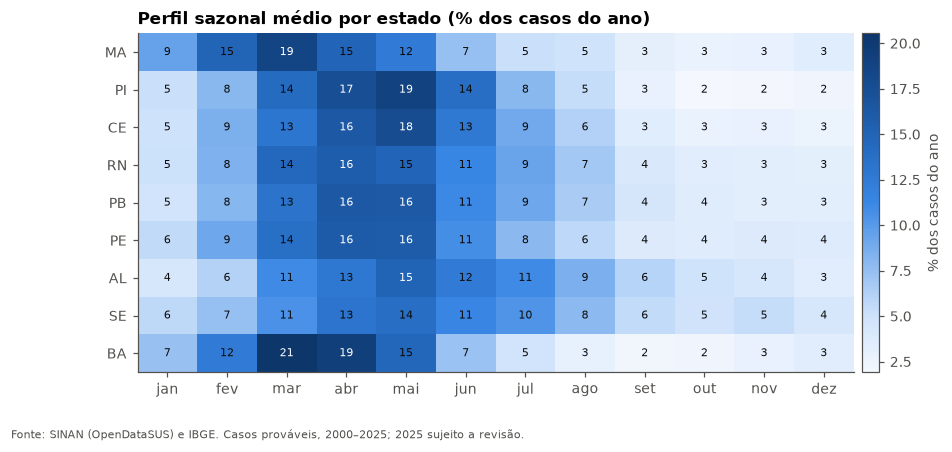

In [5]:
perfil_uf = prop_uf.groupby("uf", observed=True).mean().loc[eda.UFS]
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(perfil_uf, aspect="auto", cmap=eda.SEQUENCIAL)
for i, uf in enumerate(perfil_uf.index):
    for j in range(12):
        v = perfil_uf.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 15 else eda.COR["texto"])
ax.set_xticks(range(12), eda.MESES)
ax.set_yticks(range(len(perfil_uf)), perfil_uf.index)
ax.grid(False)
ax.set_title("Perfil sazonal médio por estado (% dos casos do ano)")
fig.colorbar(im, ax=ax, label="% dos casos do ano", pad=0.01)
eda.nota(fig)
plt.show()

## 4. Mês de pico e consistência por estado
**% anos perto do típico** = parcela dos anos em que o pico caiu a até 1 mês do pico típico do estado: quanto maior,
mais previsível a sazonalidade.

In [6]:
linhas = []
for uf in eda.UFS:
    c = circ_uf.loc[uf]
    tipico = eda.media_circular(c.pico)
    linhas.append({
        "uf": uf, "anos": len(c), "pico típico": eda.nome_mes(tipico), "pico (mês)": tipico,
        "% anos perto do típico": (eda.distancia_meses(c.pico, tipico) <= 1).mean() * 100,
        "R mediano": c.R.median(),
        "% jan–jun": prop_uf.loc[uf][range(1, 7)].sum(axis=1).median(),
    })
saz_uf = pd.DataFrame(linhas).set_index("uf")
saz_uf.sort_values("pico (mês)").round(2)

,anos,pico típico,pico (mês),% anos perto do típico,R mediano,% jan–jun
uf,,,,,,
MA,26,mar,3.46,76.92,0.49,79.67
BA,26,abr,3.66,84.62,0.53,82.37
PE,26,mai,4.54,57.69,0.45,68.21
PI,26,mai,4.55,80.77,0.52,78.33
CE,26,mai,4.65,73.08,0.50,74.18
RN,26,mai,4.67,57.69,0.47,69.37
PB,25,mai,4.72,64.00,0.45,70.06
SE,26,mai,5.13,46.15,0.39,60.76
AL,26,mai,5.40,53.85,0.41,63.11


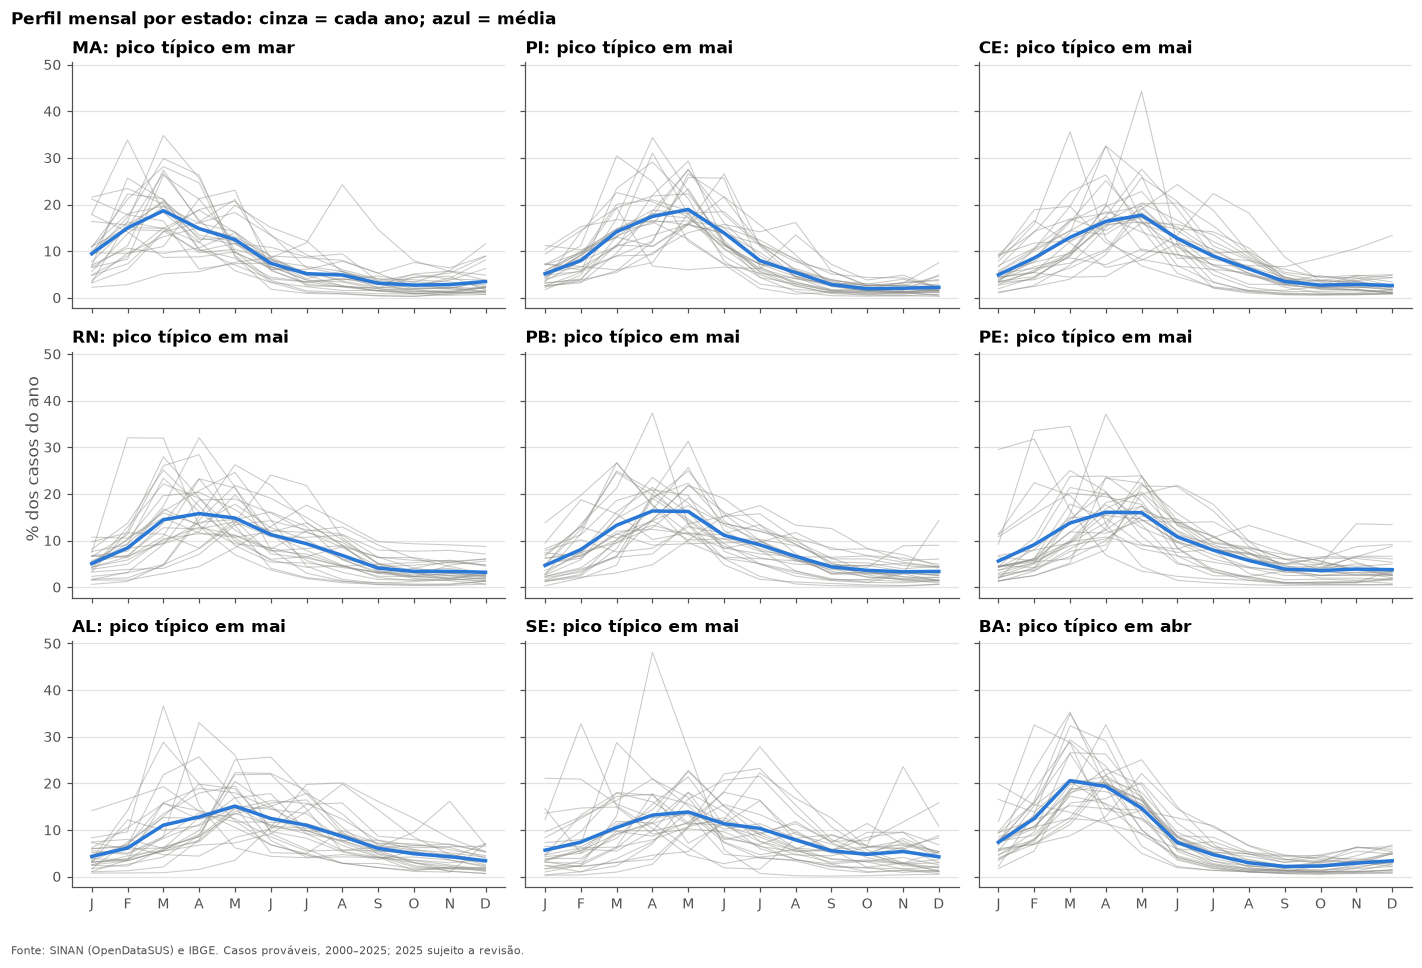

In [7]:
fig, axs = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, uf in zip(axs.ravel(), eda.UFS):
    for _, linha in prop_uf.loc[uf].iterrows():
        ax.plot(range(1, 13), linha, color=eda.COR["referencia"], lw=0.7, alpha=0.45)
    ax.plot(range(1, 13), perfil_uf.loc[uf], color=eda.COR["principal"], lw=2.3)
    ax.set_title(f"{uf}: pico típico em {saz_uf.loc[uf, 'pico típico']}")
    ax.set_xticks(range(1, 13), [m[0].upper() for m in eda.MESES])
fig.supylabel("% dos casos do ano", color=eda.COR["texto2"])
fig.suptitle("Perfil mensal por estado: cinza = cada ano; azul = média", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
eda.nota(fig)
plt.show()

## 5. Capital × interior
Aproximação provisória de litoral × semiárido (ver o topo). Mesma normalização: cada estado-grupo-ano vira proporção
mensal, com pelo menos 100 casos.

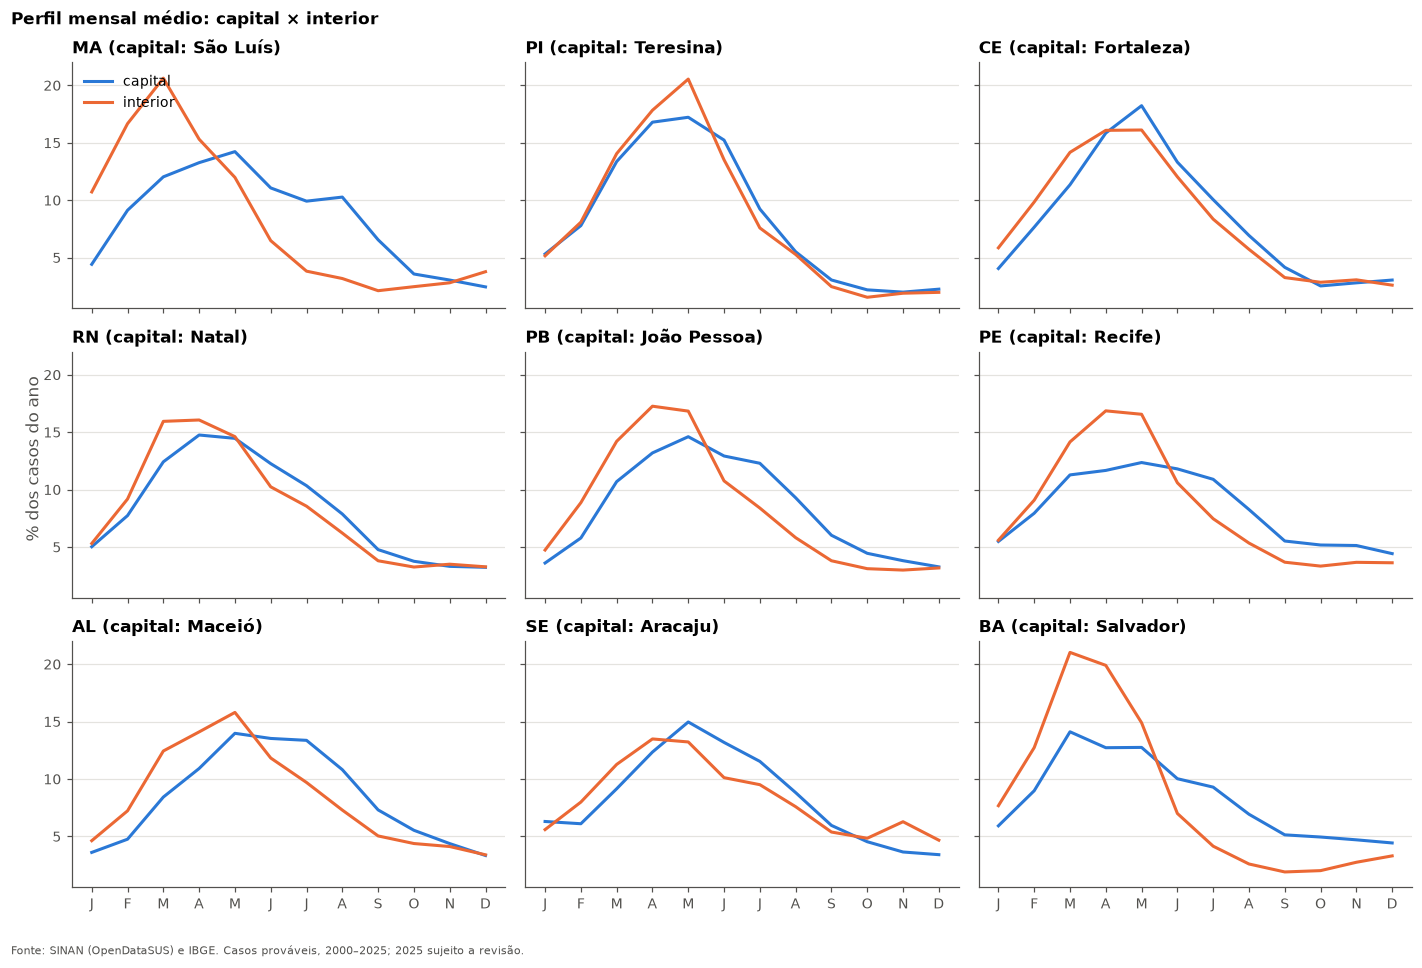

In [8]:
prop_g = proporcao_mensal(mes, ["uf", "grupo"])
circ_g = circulares(prop_g)
perfil_g = prop_g.groupby(["uf", "grupo"], observed=True).mean()
cor_g = {"capital": eda.COR["principal"], "interior": eda.COR["comparacao"]}

fig, axs = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, uf in zip(axs.ravel(), eda.UFS):
    for g in ("capital", "interior"):
        ax.plot(range(1, 13), perfil_g.loc[(uf, g)], color=cor_g[g], label=g)
    ax.set_title(f"{uf} (capital: {eda.CAPITAL_UF[uf]})")
    ax.set_xticks(range(1, 13), [m[0].upper() for m in eda.MESES])
axs[0, 0].legend(loc="upper left")
fig.supylabel("% dos casos do ano", color=eda.COR["texto2"])
fig.suptitle("Perfil mensal médio: capital × interior", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
eda.nota(fig)
plt.show()

In [9]:
linhas = []
for uf in eda.UFS:
    linha = {"uf": uf}
    for g in ("capital", "interior"):
        c = circ_g.loc[(uf, g)]
        linha[f"pico {g}"] = eda.media_circular(c.pico)
        linha[f"R {g}"] = c.R.median()
        linha[f"anos {g}"] = len(c)
    d = linha["pico interior"] - linha["pico capital"]
    linha["interior − capital (meses)"] = (d + 6) % 12 - 6          # diferença circular, de −6 a +6
    linhas.append(linha)
comp = pd.DataFrame(linhas).set_index("uf")
comp.insert(0, "mês capital", comp["pico capital"].map(eda.nome_mes))
comp.insert(1, "mês interior", comp["pico interior"].map(eda.nome_mes))
comp.round(2)

,mês capital,mês interior,pico capital,R capital,anos capital,pico interior,R interior,anos interior,interior − capital (meses)
uf,,,,,,,,,
MA,mai,mar,5.13,0.45,25,3.21,0.53,26,-1.92
PI,mai,mai,4.64,0.56,26,4.51,0.56,26,-0.13
CE,mai,abr,4.97,0.61,25,4.40,0.53,26,-0.57
RN,mai,abr,4.94,0.43,26,4.45,0.46,26,-0.49
PB,mai,mai,5.46,0.51,25,4.54,0.49,25,-0.91
PE,mai,abr,5.40,0.38,26,4.48,0.45,26,-0.92
AL,jun,mai,5.95,0.43,26,5.21,0.44,26,-0.74
SE,mai,mai,5.33,0.41,25,5.03,0.39,26,-0.30
BA,abr,abr,4.48,0.39,26,3.59,0.56,26,-0.89


## 6. Achados
- **Sazonalidade consistente:** no Nordeste, a mediana é de 75% dos casos do ano entre janeiro e junho (de 59% a 92%
  conforme o ano). O pico típico é em abril, e em 77% dos anos o pico caiu a até 1 mês dele.
- **Diferença entre estados:** o pico vem mais cedo no MA (março) e na BA (abril) e mais tarde em AL e SE (maio, perto
  de junho). BA é o estado mais previsível (85% dos anos perto do pico típico; R 0,53); SE e AL são os menos previsíveis
  (46% e 54%) e menos concentrados (R 0,39 e 0,41).
- **Capital × interior:** o pico do interior vem antes do da capital nos 9 estados, de 0,1 mês (PI) a 1,9 mês (MA). As
  capitais têm pico em maio em quase todos os estados (AL em junho, BA em abril).
- **Limite:** capital × interior é só uma aproximação de litoral × semiárido; a comparação certa depende da lista
  oficial de municípios do semiárido.